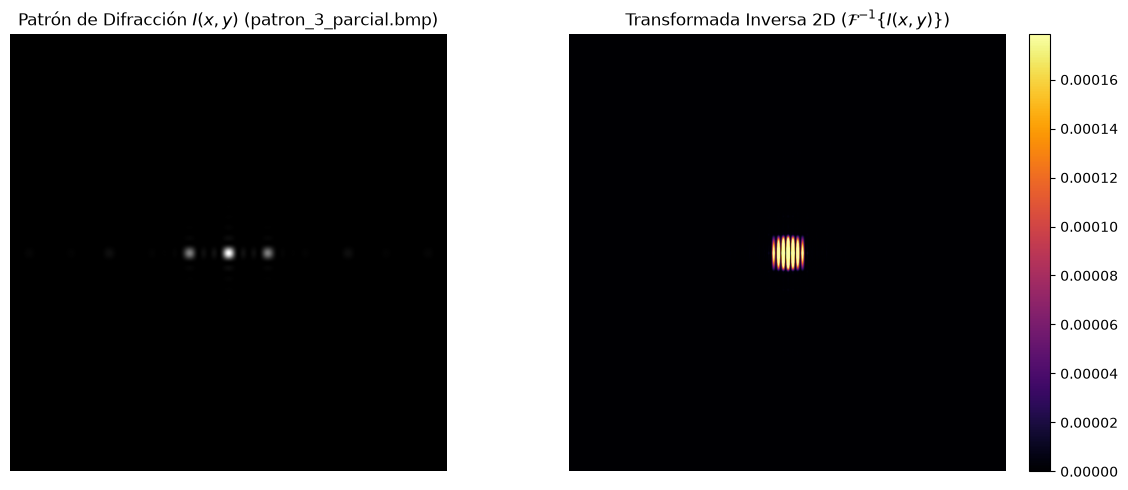

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import os

ruta_imagen = 'patron_3_parcial.bmp'

if not os.path.exists(ruta_imagen):
    raise FileNotFoundError(f"No se encontró '{ruta_imagen}' en la carpeta actual: {os.getcwd()}")

img = np.array(Image.open(ruta_imagen).convert('L'), dtype=float)
I = img / 255.0

F_inv = np.fft.ifft2(I)
F_inv_shift = np.fft.fftshift(F_inv)

magnitud = np.abs(F_inv_shift)
magnitud_log = np.log1p(magnitud)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(img, cmap='gray')
axes[0].set_title(r'Patrón de Difracción $I(x,y)$ (patron_3_parcial.bmp)')
axes[0].axis('off')

vmax_val = np.percentile(magnitud_log, 99.8)
im = axes[1].imshow(magnitud_log, cmap='inferno', vmin=0, vmax=vmax_val)
axes[1].set_title(r'Transformada Inversa 2D ($\mathcal{F}^{-1}\{I(x,y)\}$)')
axes[1].axis('off')

plt.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)
plt.tight_layout()
plt.savefig('resultado_parcial2png', dpi=300)
plt.show()

In [38]:

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from scipy.signal import find_peaks
from scipy.ndimage import gaussian_filter1d

ruta_imagen = 'patron_3_parcial.bmp'

escala_px_mm = 32.0
lambda_m = 632.8e-9
z_m = 0.50

img = np.array(
    Image.open(ruta_imagen).convert('L'),
    dtype=float
)

cy = img.shape[0] // 2

perfil = np.mean(
    img[cy-5:cy+6, :],
    axis=0
)

perfil_suave = gaussian_filter1d(
    perfil,
    sigma=2
)
picos, propiedades = find_peaks(
    perfil_suave,
    prominence=3,
    distance=8
)
picos_principales = np.array([246, 300, 354])
separaciones = np.diff(picos_principales)
delta_px = np.mean(separaciones)
delta_mm = delta_px / escala_px_mm
delta_m = delta_mm * 1e-3

d_m = (lambda_m * z_m) / delta_m
d_mm = d_m * 1e3
frecuencia_mm = 1 / d_mm
frecuencia_m = 1 / d_m
# Profesor, aquí me surge una duda. Con los picos que saque (246, 300 y 354 px) obtengo una separación
# de 54 px = 1.69 mm (con 32 px/mm), y usando d = λz/Δ = (632.8e-9 · 0.5)/(1.69e-3) ≈ 0.1875 mm
# me da una frecuencia espacial de 5.33 mm^-1 (5333 m^-1). Pero según las opciones del ejercicio, la
# respuesta debería ser aproximadamente 40 mm^-1 o 400 mm^-1. Revisé las cuentas y la fórmula
# (f = 1/d = Δ/(λz)) y no encontré el error. Para obtener 40 mm^-1 la separación entre órdenes
# tendría que ser de unos 405 px (12.7 mm), y para 400 mm^-1 de unos 4050 px, entonces no se que esta mal
print(f"Frecuencia espacial: {frecuencia_mm:.4f} mm^-1")
print(f"Frecuencia espacial: {frecuencia_m:.2f} m^-1")


Frecuencia espacial: 5.3334 mm^-1
Frecuencia espacial: 5333.44 m^-1


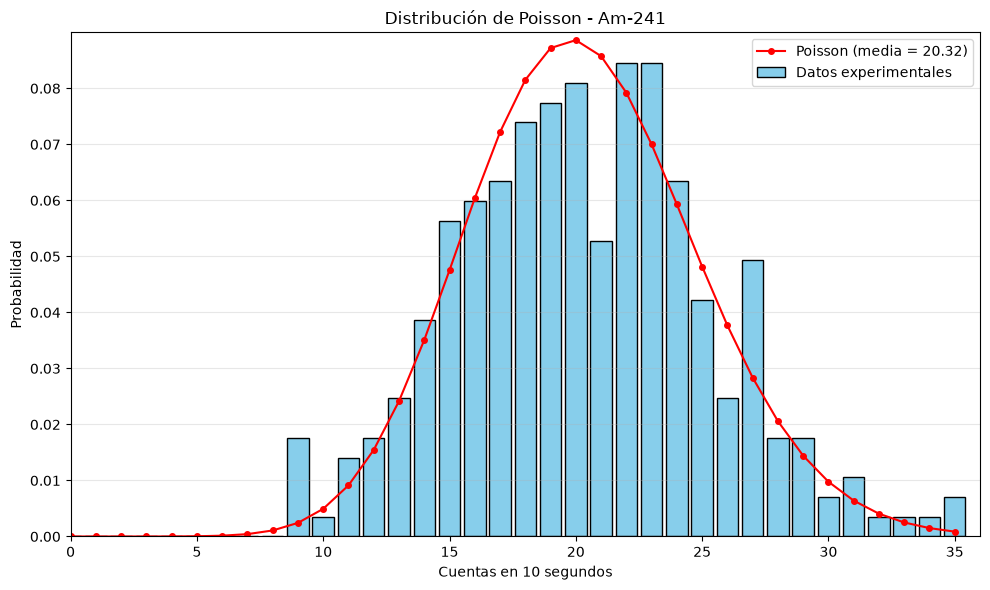

In [25]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import poisson

acumuladas = np.loadtxt('cuentas_10s_Am241.txt')

cuentas = acumuladas[:-1] - acumuladas[1:]

media = np.mean(cuentas)
k = np.arange(0, 36)
probabilidades = np.array([
    np.sum(cuentas == i) / len(cuentas)
    for i in k
])

P_poisson = poisson.pmf(k, media)

plt.figure(figsize=(10, 6))

plt.bar(
    k, probabilidades,
    width=0.85,
    color='skyblue',
    edgecolor='black',
    label='Datos experimentales'
)

plt.plot(
    k, P_poisson,
    'ro-',
    markersize=4,
    label=f'Poisson (media = {media:.2f})'
)

plt.xlim(0, 36)
plt.ylim(0, 0.09)

plt.xticks(np.arange(0, 36, 5))
plt.yticks(np.arange(0, 0.081, 0.01))

plt.xlabel('Cuentas en 10 segundos')
plt.ylabel('Probabilidad')
plt.title('Distribución de Poisson - Am-241')

plt.grid(axis='y', alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()



In [ ]:
import numpy as np
from scipy.stats import poisson

acumuladas = np.loadtxt('cuentas_10s_Am241.txt')

cuentas = -np.diff(acumuladas) 
print(cuentas[:10], cuentas.min()) 

media_10s = np.mean(cuentas)
media_60s = 6 * media_10s

P84 = poisson.pmf(84, media_60s)

print("Media cada 10 s:", media_10s)
print("Media cada minuto:", media_60s)
print("P(84 cuentas):", P84, f"= {100*P84:.4f} %")

#pfesor aqui me surge una duda,estube baastante rato pensando en porque no me daba y no se porque es valido que si divido por 6 el valor de 84,la 
# probabilidad es la misma que de 84, entiendo que es porque la media de 10s es 20.32 y la de 60s es 121.94, entonces si divido 84/6=14,
# y la media de 10s es 20.32, entonces la probabilidad de que salga 14 cuentas en 10s es la misma que la probabilidad de que salga 84 cuentas en 60s,
#  ya que el promedio de cuentas por segundo es el mismo, pero no se si estoy en lo correcto
from scipy.stats import poisson

media_10s = 20.323943661971832
P = poisson.pmf(84/6, media_10s)  
print(P, f"= {100*P:.2f} %")       

[17. 23. 31. 19. 21. 26.  9. 27. 15. 16.] 9.0
Media cada 10 s: 20.323943661971832
Media cada minuto: 121.94366197183099
P(84 cuentas): 5.72179220895542e-05 = 0.0057 %
0.035085431191094855 = 3.51 %


In [29]:

import numpy as np
from scipy.stats import t

n = 51
media = 9.889
desviacion = 0.845

alpha = 0.05

gl = n - 1

factor_t = t.ppf(1 - alpha/2, gl)

error = factor_t * desviacion / np.sqrt(n)

limite_inferior = media - error
limite_superior = media + error

print(f"Grados de libertad: {gl}")
print(f"Factor de Student: {factor_t:.3f}")
print(f"Error: {error:.3f} m/s²")

print(f"Intervalo de confianza:")
print(f"({limite_inferior:.2f}, {limite_superior:.2f}) m/s²")


Grados de libertad: 50
Factor de Student: 2.009
Error: 0.238 m/s²
Intervalo de confianza:
(9.65, 10.13) m/s²
